# Mall Customer Segmentation using Clustering

**Goal:** group a mall's customers into segments that share similar demographics and spending habits, so marketing can target each segment differently.

**Dataset:** `Mall_Customers.csv` has 200 customers with five columns: `CustomerID`, `Gender`, `Age`, `Annual Income (k$)` and `Spending Score (1-100)`. The spending score is assigned by the mall based on purchase behaviour.

**Approach:**
1. Exploratory data analysis (distributions, gender split, correlations, skewness)
2. Cluster on several feature pairs and on all three numeric features, using **K-Means** and **Hierarchical (Agglomerative, Ward) clustering**
3. Choose the number of clusters with the elbow method, dendrograms **and silhouette scores**
4. Compare the two algorithms (Adjusted Rand Index) and profile each segment into actionable business groups

# Importing Libraries

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.express as px
import plotly.io as pio
import scipy.cluster.hierarchy as sch
import seaborn as sns
from scipy import stats
from scipy.stats import boxcox, norm
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.metrics import adjusted_rand_score, davies_bouldin_score, silhouette_score
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)
pio.renderers.default = "plotly_mimetype+notebook_connected"
sns.set_style("darkgrid")
RANDOM_STATE = 42

# Loading Dataset

In [2]:
dataset = pd.read_csv("Mall_Customers.csv", index_col="CustomerID")
INCOME, SCORE, AGE = "Annual Income (k$)", "Spending Score (1-100)", "Age"
NUMERIC_COLS = [AGE, INCOME, SCORE]

# Exploratory Data Analysis

## 1) Using Manual Methods

In [3]:
dataset.head()

,Gender,Age,Annual Income (k$),Spending Score (1-100)
CustomerID,,,,
1,Male,19,15,39
2,Male,21,15,81
3,Female,20,16,6
4,Female,23,16,77
5,Female,31,17,40


In [4]:
dataset.shape

(200, 4)

In [5]:
dataset.describe().T

,count,mean,std,min,25%,50%,75%,max
Age,200.0,38.85,13.969007,18.0,28.75,36.0,49.0,70.0
Annual Income (k$),200.0,60.56,26.264721,15.0,41.50,61.5,78.0,137.0
Spending Score (1-100),200.0,50.20,25.823522,1.0,34.75,50.0,73.0,99.0


In [6]:
dataset.info()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 1 to 200
Data columns (total 4 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   Gender                  200 non-null    str  
 1   Age                     200 non-null    int64
 2   Annual Income (k$)      200 non-null    int64
 3   Spending Score (1-100)  200 non-null    int64
dtypes: int64(3), str(1)
memory usage: 7.4 KB


In [7]:
print("Missing values:", dataset.isnull().values.any())
print("Duplicate rows:", dataset.duplicated().sum())

Missing values: False
Duplicate rows: 0


## Plotting Count for Annual Income

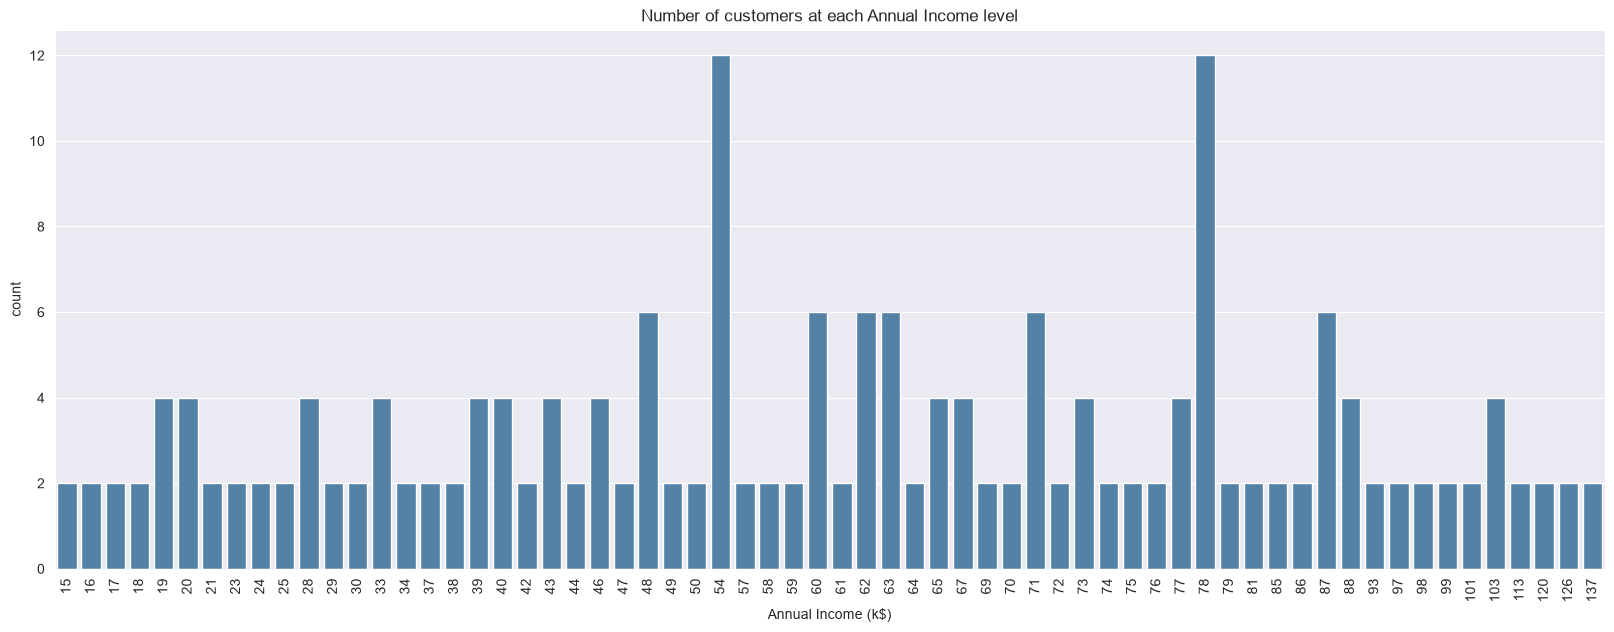

In [8]:
plt.figure(figsize=(20, 7))
sns.countplot(x=INCOME, data=dataset, color="steelblue")
plt.xticks(rotation=90)
plt.title("Number of customers at each Annual Income level")
plt.show()

## Finding Correlation among the variables

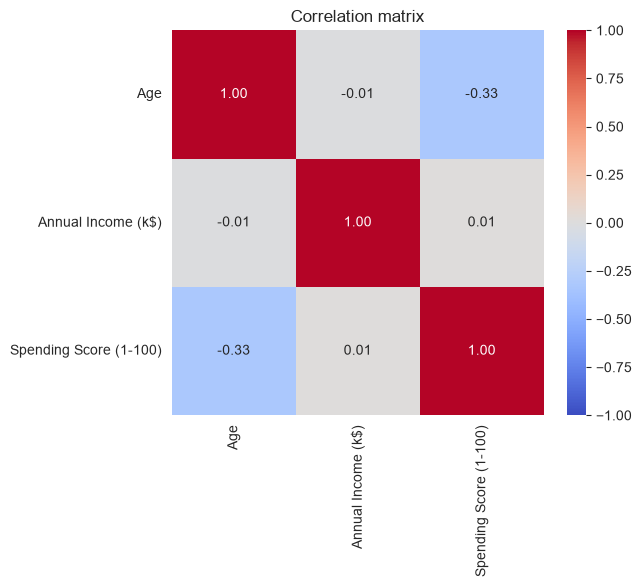

In [9]:
plt.figure(figsize=(6, 5))
sns.heatmap(dataset[NUMERIC_COLS].corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation matrix")
plt.show()

The correlations are weak. The strongest is a moderate negative one between **Age and Spending Score** (younger customers tend to spend more). **Income and Spending Score are almost uncorrelated**, so a straight line can't separate customers on those two features, but clustering can find groups in them.

## Plotting Distribution for each Column in dataset

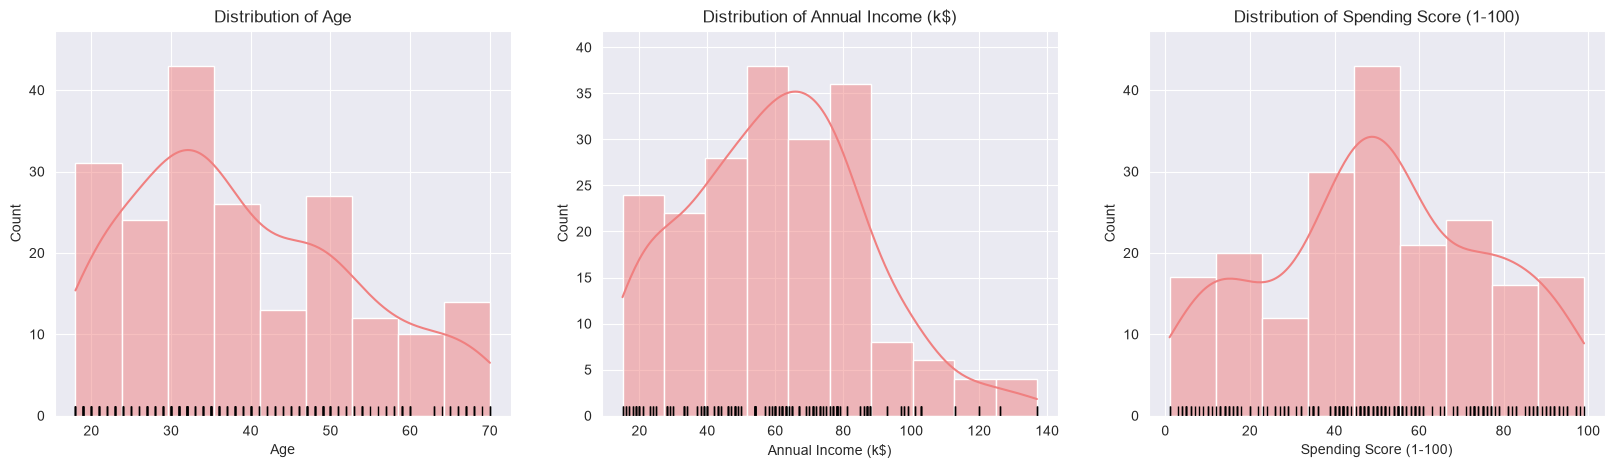

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(20, 5))
for ax, col in zip(axes, NUMERIC_COLS):
    sns.histplot(dataset[col], kde=True, color="lightcoral", ax=ax)
    sns.rugplot(dataset[col], color="black", ax=ax)
    ax.set_title(f"Distribution of {col}")
plt.show()

## Distribution of Males and Females in dataset

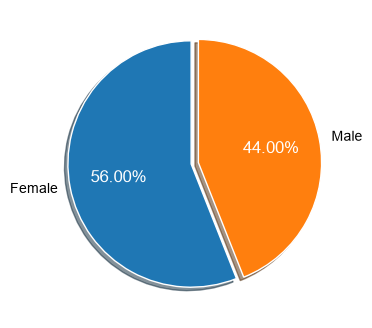

Gender
Female    112
Male       88
Name: count, dtype: int64

In [11]:
values = dataset["Gender"].value_counts()   # labels come from the data, not hard-coded

fig, ax = plt.subplots(figsize=(4, 4), dpi=100)
patches, texts, autotexts = ax.pie(values, labels=values.index, autopct="%1.2f%%", shadow=True,
                                   startangle=90, explode=(0, 0.06))
plt.setp(texts, color="black")
plt.setp(autotexts, size=12, color="white")
plt.show()
values

## Plotting Distribution of Males in dataset

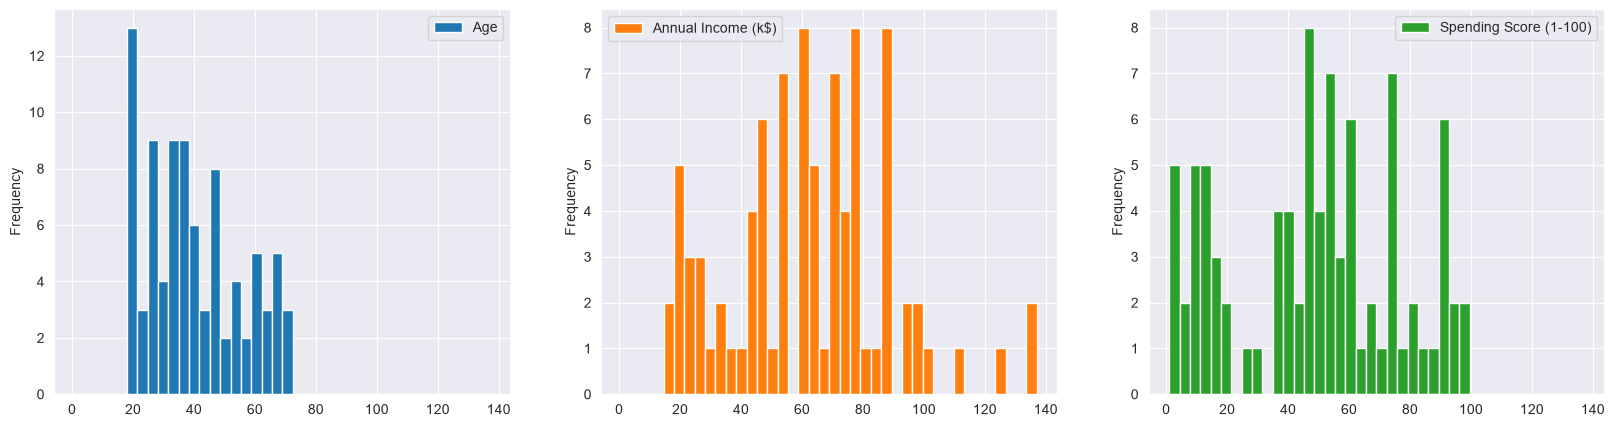

In [12]:
sdat = dataset.groupby(by="Gender")
fig, ax = plt.subplots(1, 3, figsize=(20, 5))
sdat.get_group("Male")[NUMERIC_COLS].plot(kind="hist", ax=ax, subplots=True, bins=40)
plt.show()

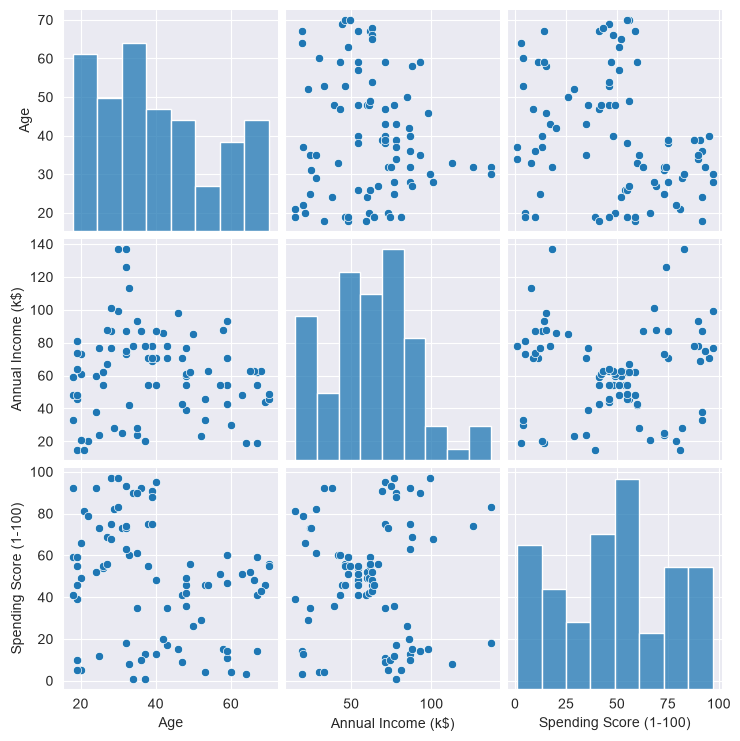

In [13]:
sns.pairplot(sdat.get_group("Male")[NUMERIC_COLS]);

## Plotting Distribution of Females in dataset

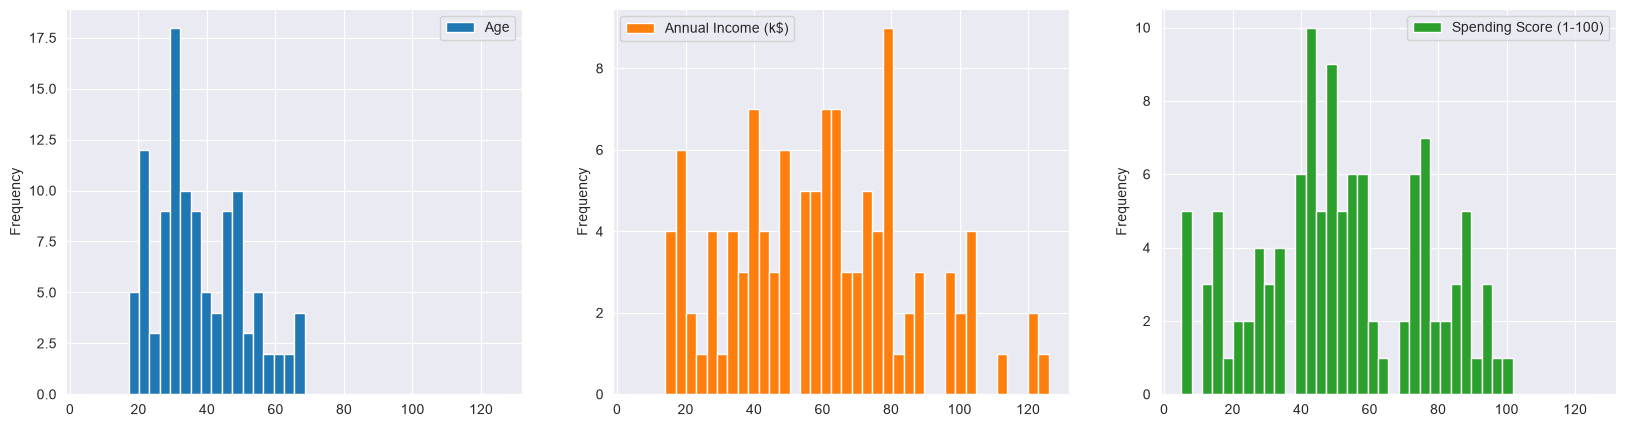

In [14]:
fig, ax = plt.subplots(1, 3, figsize=(20, 5))
sdat.get_group("Female")[NUMERIC_COLS].plot(kind="hist", ax=ax, subplots=True, bins=40)
plt.show()

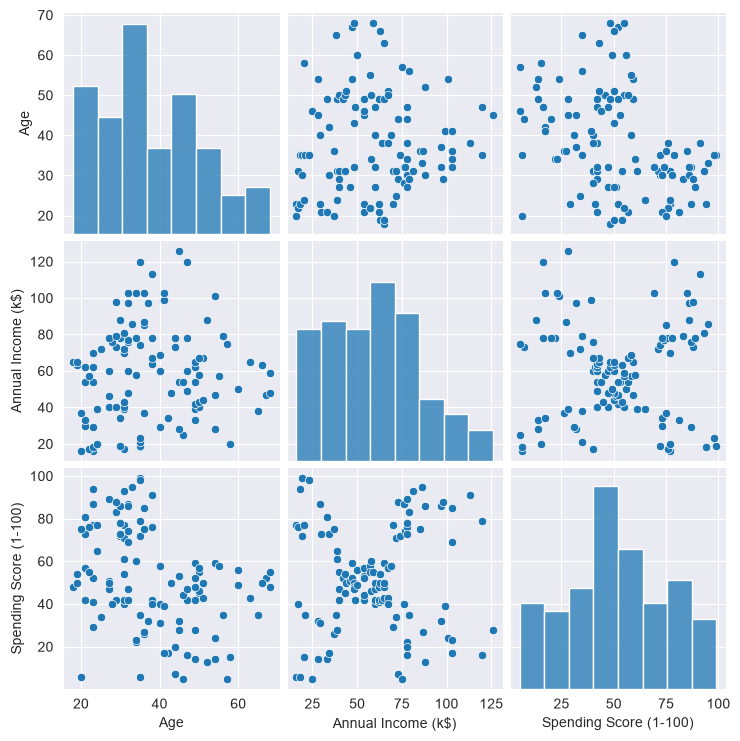

In [15]:
sns.pairplot(sdat.get_group("Female")[NUMERIC_COLS]);

## Comparing Males and Females

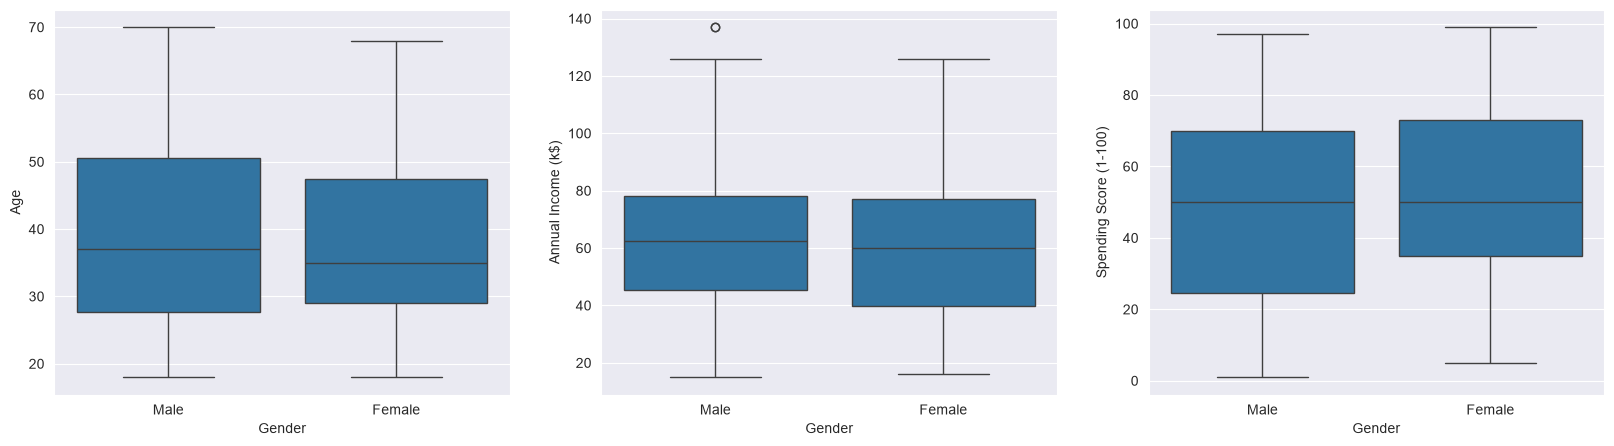

,Age,Annual Income (k$),Spending Score (1-100)
Gender,,,
Female,38.1,59.2,51.5
Male,39.8,62.2,48.5


In [16]:
fig, axes = plt.subplots(1, 3, figsize=(20, 5))
for ax, col in zip(axes, NUMERIC_COLS):
    sns.boxplot(data=dataset, x="Gender", y=col, ax=ax)
plt.show()
dataset.groupby("Gender")[NUMERIC_COLS].mean().round(1)

Men and women look very similar on all three features. Gender is categorical, and plain Euclidean K-Means doesn't handle a binary feature well, so **Gender is left out of the clustering**. It is still reported in the segment profiles at the end.

## Skewness Check

Before clustering, we check whether any feature is strongly skewed and test what a Box-Cox transformation would do. **The transformation is applied to a copy for inspection only, not to the data used for clustering**, because:

- the skew is mild (|skew| < 0.5 for every feature), and K-Means doesn't require normally distributed features;
- transforming would put the clusters on an unreadable scale (e.g. income would range from about 7 to 36 instead of 15–137 k$), which makes the segments hard to explain to the business.

In [17]:
dataset[NUMERIC_COLS].skew().round(3).to_frame("skewness")

,skewness
Age,0.486
Annual Income (k$),0.322
Spending Score (1-100),-0.047


In [18]:
def skewnessCorrector(series):
    """Shows the distribution and Q-Q plot before and after Box-Cox (does NOT modify the dataset)."""
    transformed, lam = boxcox(series)
    transformed = pd.Series(transformed, index=series.index)
    fig, axes = plt.subplots(1, 4, figsize=(24, 5))
    for (label, s, color), (ax_hist, ax_qq) in zip(
        [("Before", series, "lightcoral"), ("After", transformed, "orange")],
        [(axes[0], axes[1]), (axes[2], axes[3])],
    ):
        mu, sigma = norm.fit(s)
        sns.histplot(s, kde=True, stat="density", color=color, ax=ax_hist)
        x = np.linspace(s.min(), s.max(), 200)
        ax_hist.plot(x, norm.pdf(x, mu, sigma), "k--", lw=1)
        ax_hist.set_title(f"{series.name}: {label} Box-Cox  (mu={mu:.2f}, sigma={sigma:.2f}, skew={s.skew():.2f})")
        stats.probplot(s, plot=ax_qq)
        ax_qq.set_title(f"{label} Box-Cox Q-Q plot")
    plt.show()
    print(f"{series.name}: lambda = {lam:.3f}")

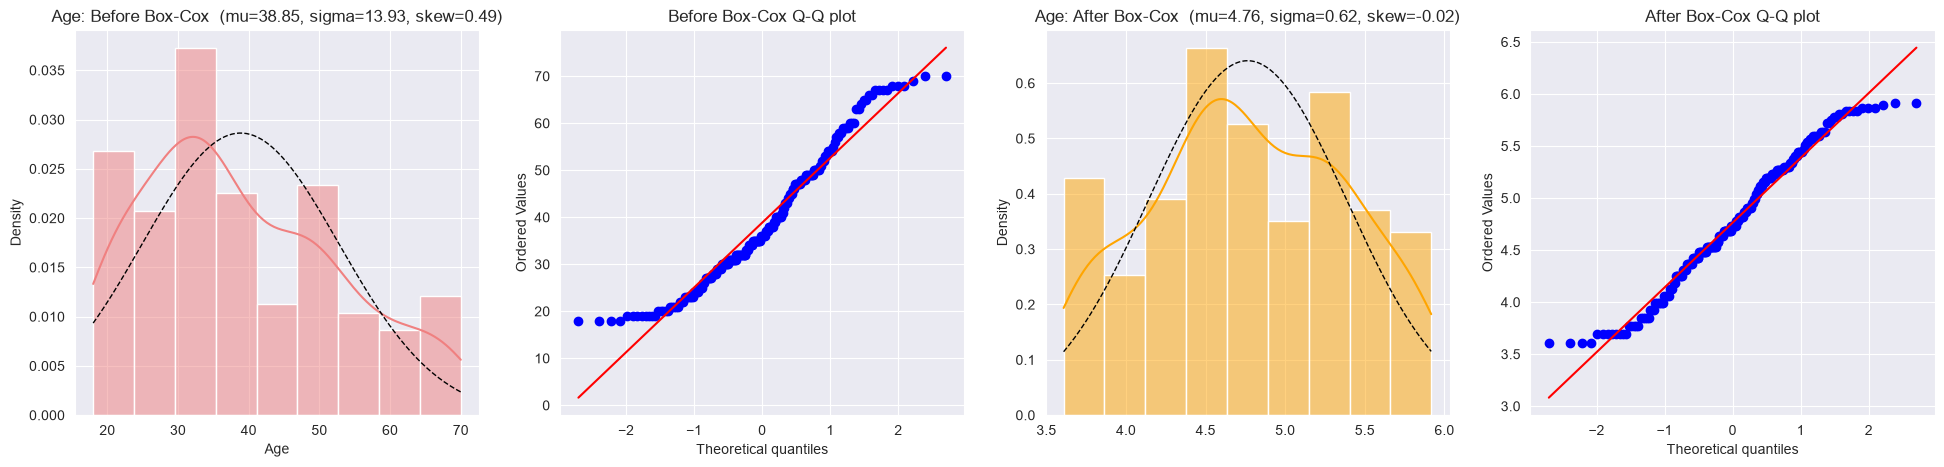

Age: lambda = 0.148


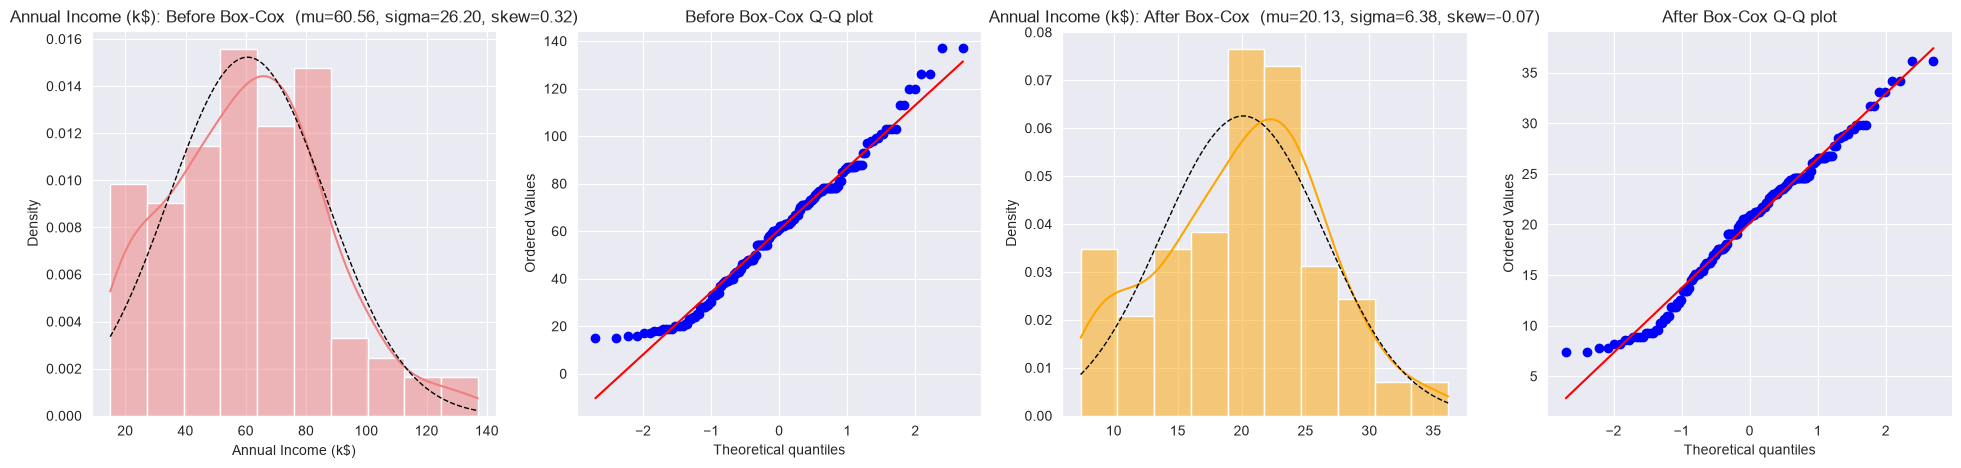

Annual Income (k$): lambda = 0.650


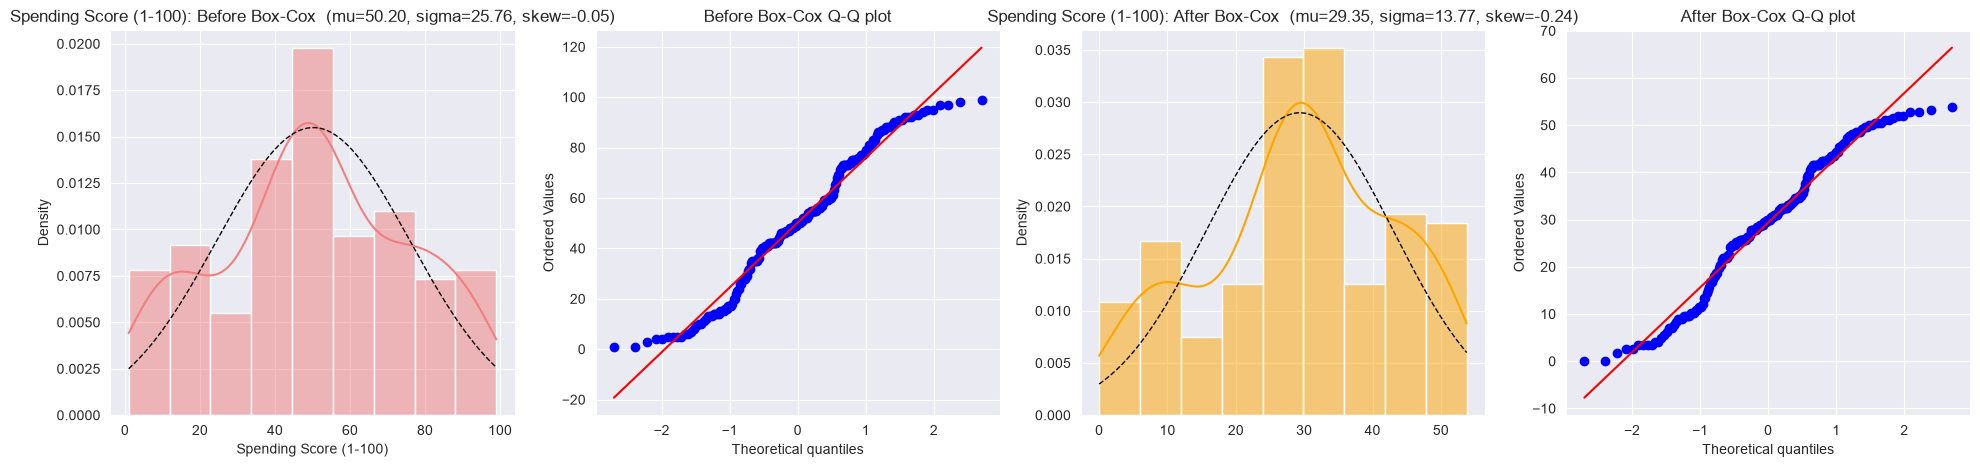

Spending Score (1-100): lambda = 0.832


In [19]:
for column in NUMERIC_COLS:
    skewnessCorrector(dataset[column])

# 2) Using Automated Profiling (optional)

`ydata-profiling` (the successor to the deprecated `pandas-profiling`) builds a full automated EDA report. It doesn't yet support Python 3.14, so the cell below only runs when the package is installed; the manual EDA above covers the same ground.

In [20]:
try:
    from ydata_profiling import ProfileReport
    ProfileReport(dataset, title="Mall Customers Profiling Report", minimal=True).to_notebook_iframe()
except ImportError:
    print("ydata-profiling not installed (run `%pip install ydata-profiling` on Python <= 3.13); skipping.")

ydata-profiling not installed (run `%pip install ydata-profiling` on Python <= 3.13); skipping.


# Training Clustering Models on Dataset

## Function to find the optimal number of clusters using the elbow method and silhouette scores

In [21]:
def elbowOptimizer(data, k_range=range(2, 11)):
    """Plots the elbow (WCSS) chart and silhouette scores, and returns a table of scores per k."""
    rows = []
    for k in k_range:
        km = KMeans(n_clusters=k, init="k-means++", n_init=10, random_state=RANDOM_STATE).fit(data)
        rows.append({"k": k, "WCSS": km.inertia_,
                     "silhouette": silhouette_score(data, km.labels_),
                     "davies_bouldin": davies_bouldin_score(data, km.labels_)})
    scores = pd.DataFrame(rows).set_index("k")
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4))
    ax1.plot(scores.index, scores["WCSS"], marker="o")
    ax1.set(title="The Elbow Method", xlabel="Number of clusters", ylabel="WCSS")
    ax2.plot(scores.index, scores["silhouette"], marker="o", color="green")
    best = scores["silhouette"].idxmax()
    ax2.axvline(best, ls="--", color="grey")
    ax2.set(title=f"Silhouette score (best k = {best})", xlabel="Number of clusters", ylabel="Silhouette")
    plt.show()
    return scores.round(3)

## Function to find optimal numbers of clusters using Dendrograms

In [22]:
def dendoOptimizer(data):
    """Plots a Dendrogram on the data provided (Ward linkage)"""
    plt.figure(figsize=(16, 6))
    sch.dendrogram(sch.linkage(data, method="ward"), no_labels=True)
    plt.title("Dendrogram")
    plt.xlabel("Customers")
    plt.ylabel("Euclidean distances (Ward)")
    plt.show()

## Function for Training K-Means Model on Given Data

In [23]:
def kmeansTrainer(numberOfClusters, data):
    """
    Trains KMeans Clustering Algorithm on data with
    number of clusters provided and Returns corresponding Model and Labels
    """
    kmeans = KMeans(n_clusters=numberOfClusters, init="k-means++", n_init=10, random_state=RANDOM_STATE)
    labels = kmeans.fit_predict(data)
    return kmeans, labels

## Function for Training Hierarchical Clustering model on given data

In [24]:
def hierarchicalTrainer(noOfClusters, data):
    """
    Trains Agglomerative Clustering Algorithm on data with
    number of clusters provided and Returns corresponding Model and Labels
    """
    hc = AgglomerativeClustering(n_clusters=noOfClusters, metric="euclidean", linkage="ward")
    hc_labels = hc.fit_predict(data)
    return hc, hc_labels

## Function for comparing the two models

In [25]:
def compareModels(data, km_labels, hc_labels):
    """Silhouette score for each model and agreement between them (Adjusted Rand Index)."""
    return pd.Series({
        "K-Means silhouette": silhouette_score(data, km_labels),
        "Hierarchical silhouette": silhouette_score(data, hc_labels),
        "Agreement (Adjusted Rand Index)": adjusted_rand_score(km_labels, hc_labels),
    }).round(3)

## Function for visualising 2-d Clusters

In [26]:
COLORS = ["red", "blue", "green", "cyan", "magenta", "purple", "orange", "brown"]

def clusterVisualiser(data, model, noOfClusters, labels, xlabel, ylabel, model_type):
    """Plots Scatter Plot for the clusters on the Data given"""
    plt.figure(figsize=(9, 6))
    for i in range(noOfClusters):
        plt.scatter(data[labels == i, 0], data[labels == i, 1], s=80, c=COLORS[i], label="Cluster " + str(i + 1))
    if model_type == "KMeans Clustering":
        plt.scatter(model.cluster_centers_[:, 0], model.cluster_centers_[:, 1],
                    s=300, c="yellow", edgecolors="black", label="Centroids")
    plt.title("Clusters of customers using " + model_type)
    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    plt.legend()
    plt.show()

## Function for profiling the clusters

In [27]:
def clusterProfile(labels):
    """Average features, size and gender mix of each cluster (on the original, readable scale)."""
    df = dataset.assign(Cluster=labels + 1)
    profile = df.groupby("Cluster")[NUMERIC_COLS].mean().round(1)
    profile["Size"] = df["Cluster"].value_counts().sort_index()
    profile["% Female"] = (df.groupby("Cluster")["Gender"].apply(lambda g: (g == "Female").mean() * 100)).round(0)
    return profile

# Clustering the dataset on Annual Income and Spending Score

In [28]:
X1 = dataset[[INCOME, SCORE]].values

## Using the elbow method and silhouette scores to find the optimal number of clusters for Annual Income and Spending Score

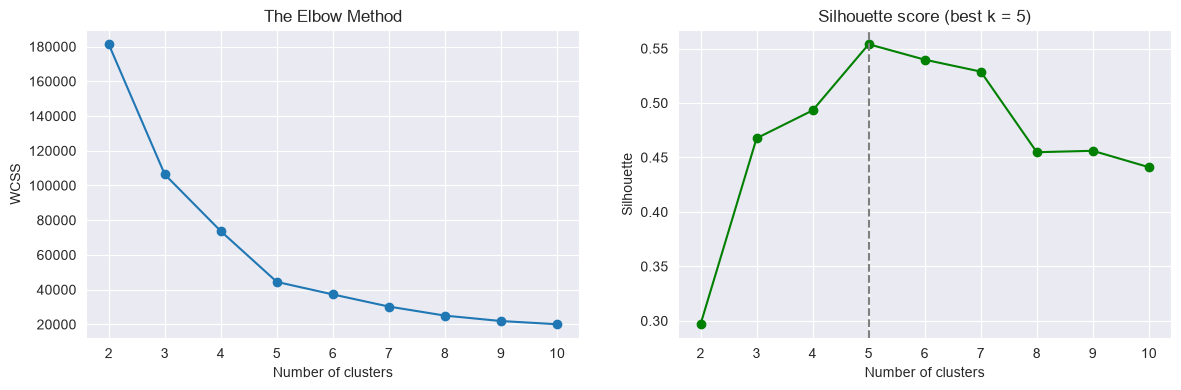

,WCSS,silhouette,davies_bouldin
k,,,
2,181363.596,0.297,1.257
3,106348.373,0.468,0.715
4,73679.789,0.493,0.710
5,44448.455,0.554,0.573
6,37233.815,0.540,0.652
7,30241.344,0.529,0.711
8,25036.418,0.455,0.759
9,21916.795,0.456,0.763
10,20072.071,0.441,0.761


In [29]:
elbowOptimizer(X1)

## Using the dendrogram to find the optimal number of clusters for Annual Income and Spending Score

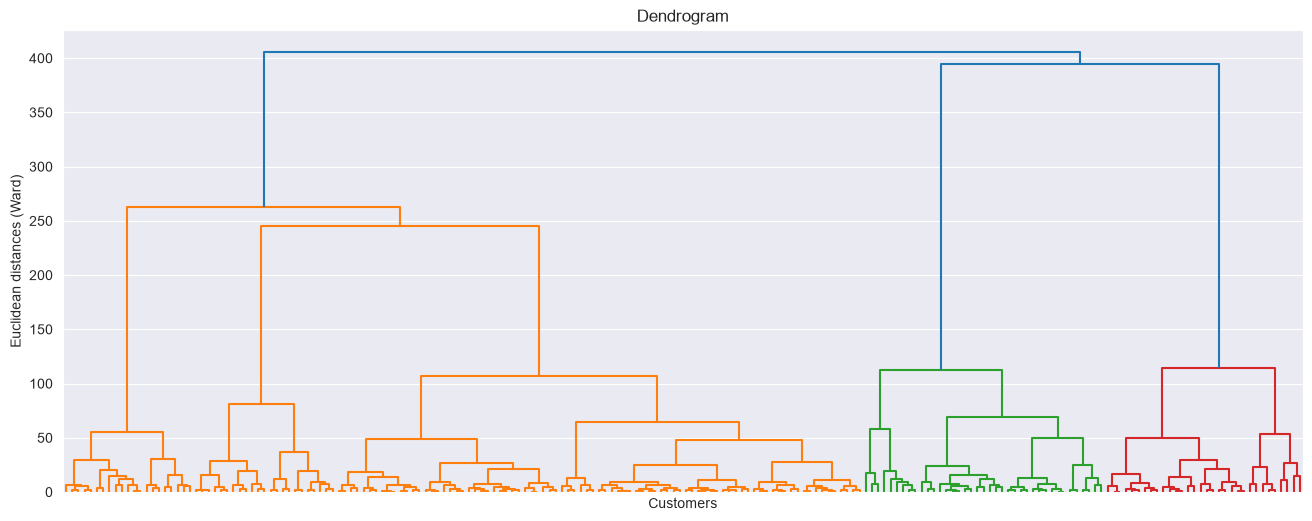

In [30]:
dendoOptimizer(X1)

**Choosing k:** the elbow bends at **k = 5**, the silhouette score is highest at k = 5 (0.554), and the dendrogram's longest vertical gap gives 5 clusters as well. All three methods agree, so we use **k = 5**.

## Training the K-Means and Hierarchical models on Annual Income and Spending Score (k = 5)

In [31]:
kmeans, labels = kmeansTrainer(5, X1)
hc, hc_labels = hierarchicalTrainer(5, X1)
compareModels(X1, labels, hc_labels)

K-Means silhouette                 0.554
Hierarchical silhouette            0.553
Agreement (Adjusted Rand Index)    0.942
dtype: float64

## Visualising the clusters for Annual Income and Spending Score (KMeans Model)

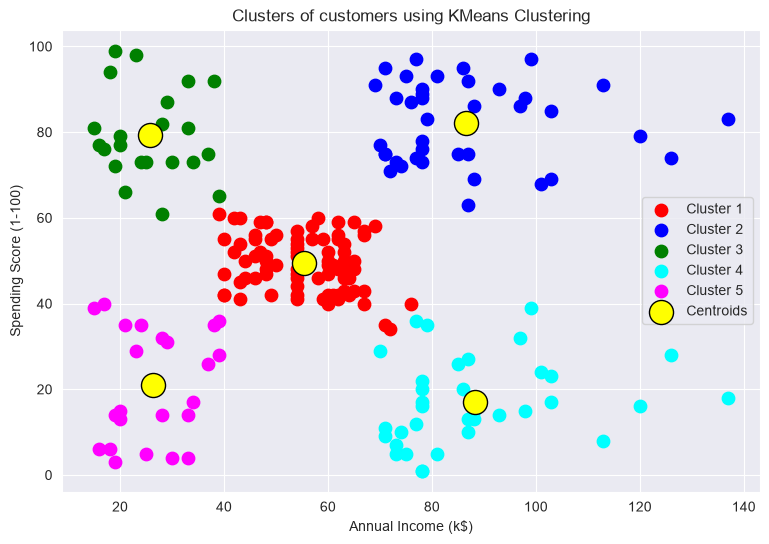

In [32]:
clusterVisualiser(X1, kmeans, 5, labels, 'Annual Income (k$)', 'Spending Score (1-100)', 'KMeans Clustering')

## Visualising the clusters for Annual Income and Spending Score (Hierarchical Model)

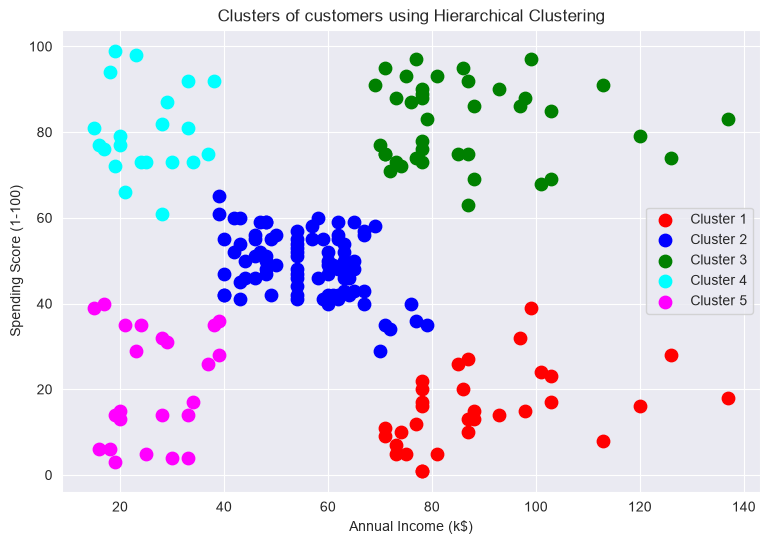

In [33]:
clusterVisualiser(X1, hc, 5, hc_labels, 'Annual Income (k$)', 'Spending Score (1-100)', 'Hierarchical Clustering')

## Cluster profiles for Annual Income and Spending Score (KMeans Model)

In [34]:
clusterProfile(labels)

,Age,Annual Income (k$),Spending Score (1-100),Size,% Female
Cluster,,,,,
1,42.7,55.3,49.5,81,59.0
2,32.7,86.5,82.1,39,54.0
3,25.3,25.7,79.4,22,59.0
4,41.1,88.2,17.1,35,46.0
5,45.2,26.3,20.9,23,61.0


# Clustering the dataset on Age and Spending Score

In [35]:
X2 = dataset[[AGE, SCORE]].values

## Using the elbow method and silhouette scores to find the optimal number of clusters for Age and Spending Score

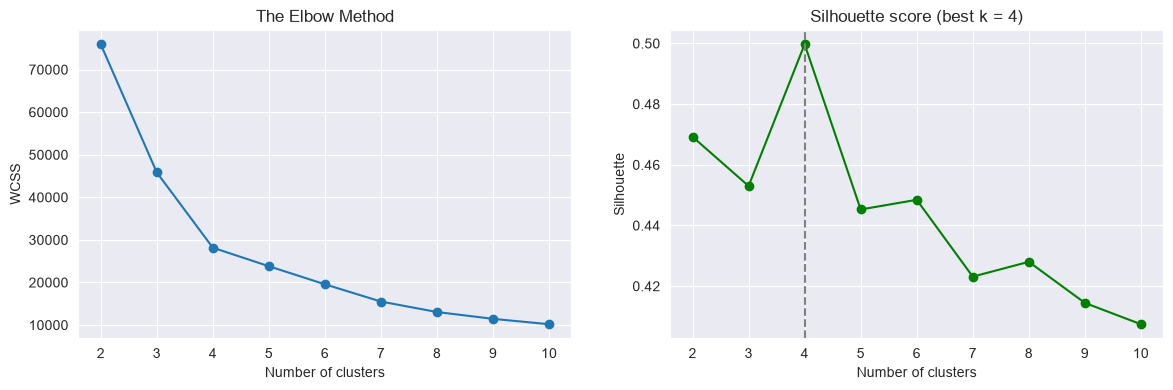

,WCSS,silhouette,davies_bouldin
k,,,
2,75949.156,0.469,0.772
3,45840.677,0.453,0.829
4,28165.584,0.500,0.687
5,23811.524,0.445,0.785
6,19566.522,0.448,0.822
7,15514.193,0.423,0.821
8,13055.627,0.428,0.774
9,11453.289,0.414,0.794
10,10186.501,0.407,0.800


In [36]:
elbowOptimizer(X2)

## Using the dendrogram to find the optimal number of clusters for Age and Spending Score

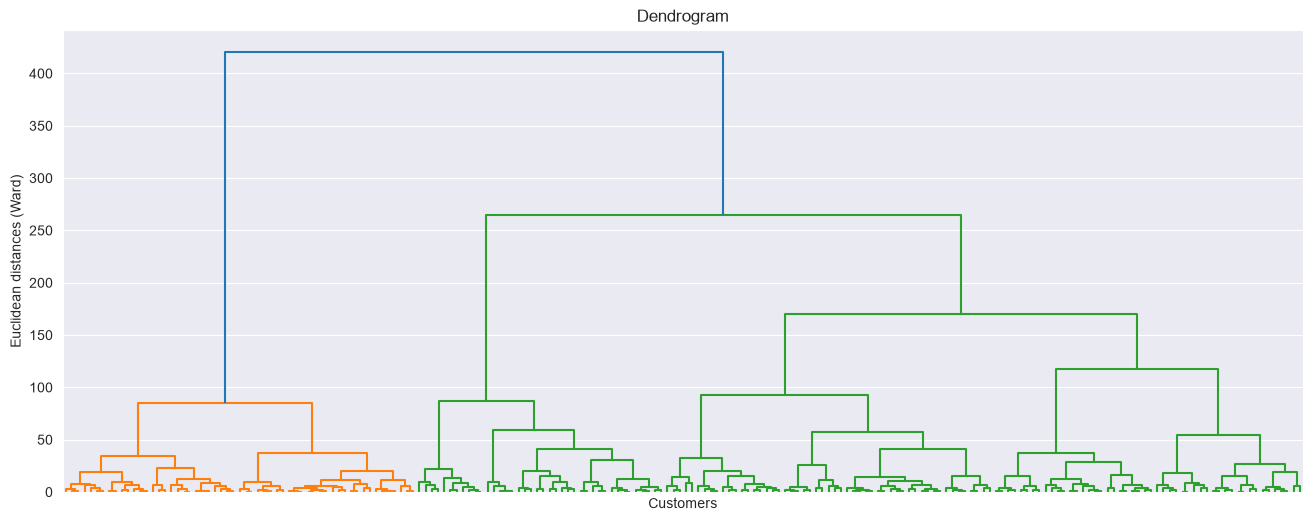

In [37]:
dendoOptimizer(X2)

**Choosing k:** the silhouette score peaks at **k = 4** (0.500), which matches the elbow, so we use **k = 4**.

## Training the K-Means and Hierarchical models on Age and Spending Score (k = 4)

In [38]:
kmeans, labels = kmeansTrainer(4, X2)
hc, hc_labels = hierarchicalTrainer(4, X2)
compareModels(X2, labels, hc_labels)

K-Means silhouette                 0.500
Hierarchical silhouette            0.460
Agreement (Adjusted Rand Index)    0.788
dtype: float64

## Visualising the clusters for Age and Spending Score (KMeans Model)

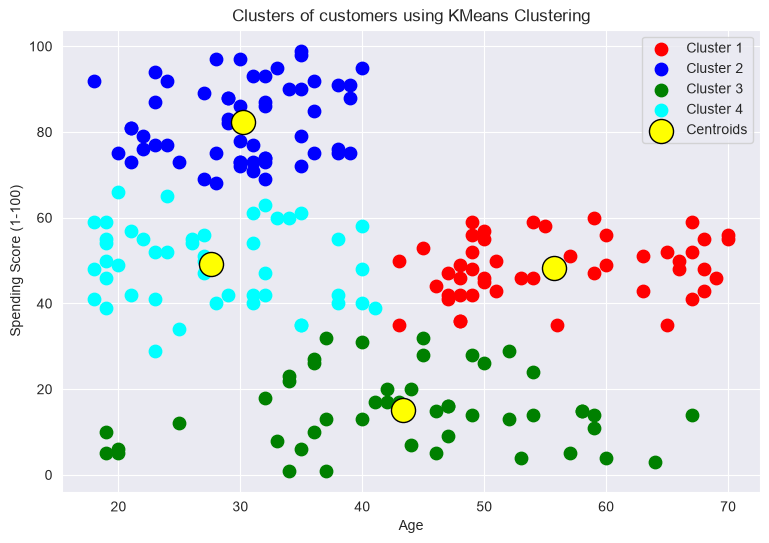

In [39]:
clusterVisualiser(X2, kmeans, 4, labels, 'Age', 'Spending Score (1-100)', 'KMeans Clustering')

## Visualising the clusters for Age and Spending Score (Hierarchical Model)

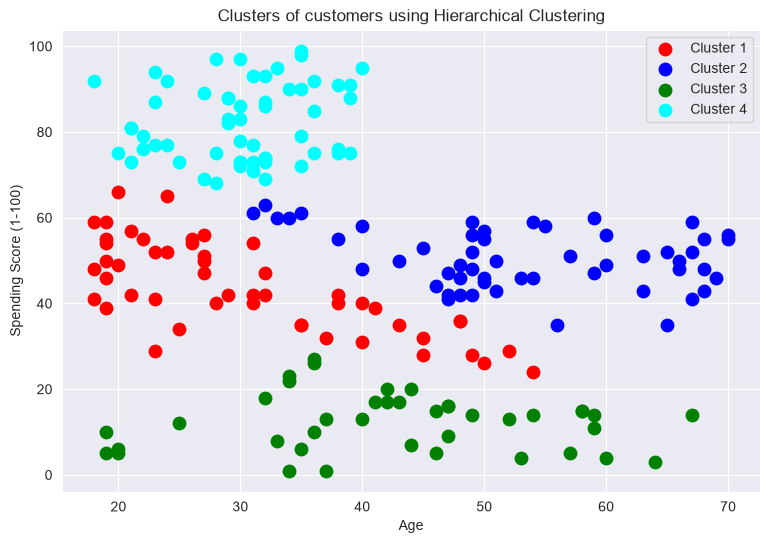

In [40]:
clusterVisualiser(X2, hc, 4, hc_labels, 'Age', 'Spending Score (1-100)', 'Hierarchical Clustering')

## Cluster profiles for Age and Spending Score (KMeans Model)

In [41]:
clusterProfile(labels)

,Age,Annual Income (k$),Spending Score (1-100),Size,% Female
Cluster,,,,,
1,55.7,54.8,48.2,48,54.0
2,30.2,66.1,82.4,57,58.0
3,43.3,66.9,15.0,48,50.0
4,27.6,53.3,49.1,47,62.0


# Clustering the dataset on Age and Annual Income

In [42]:
X3 = dataset[[AGE, INCOME]].values

## Using the elbow method and silhouette scores to find the optimal number of clusters for Age and Annual Income

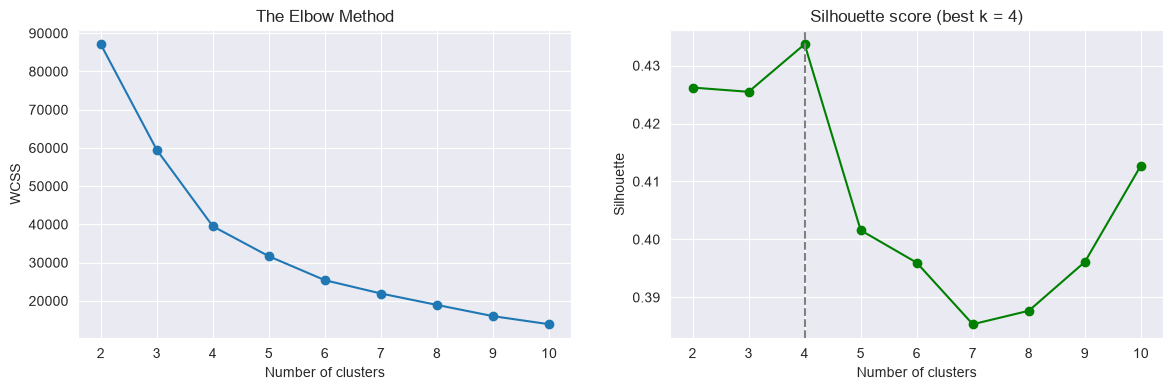

,WCSS,silhouette,davies_bouldin
k,,,
2,87121.566,0.426,0.880
3,59486.961,0.425,0.819
4,39502.779,0.434,0.769
5,31659.353,0.402,0.775
6,25399.022,0.396,0.816
7,21917.572,0.385,0.845
8,18926.730,0.388,0.826
9,15993.236,0.396,0.779
10,13879.628,0.413,0.736


In [43]:
elbowOptimizer(X3)

## Using the dendrogram to find the optimal number of clusters for Age and Annual Income

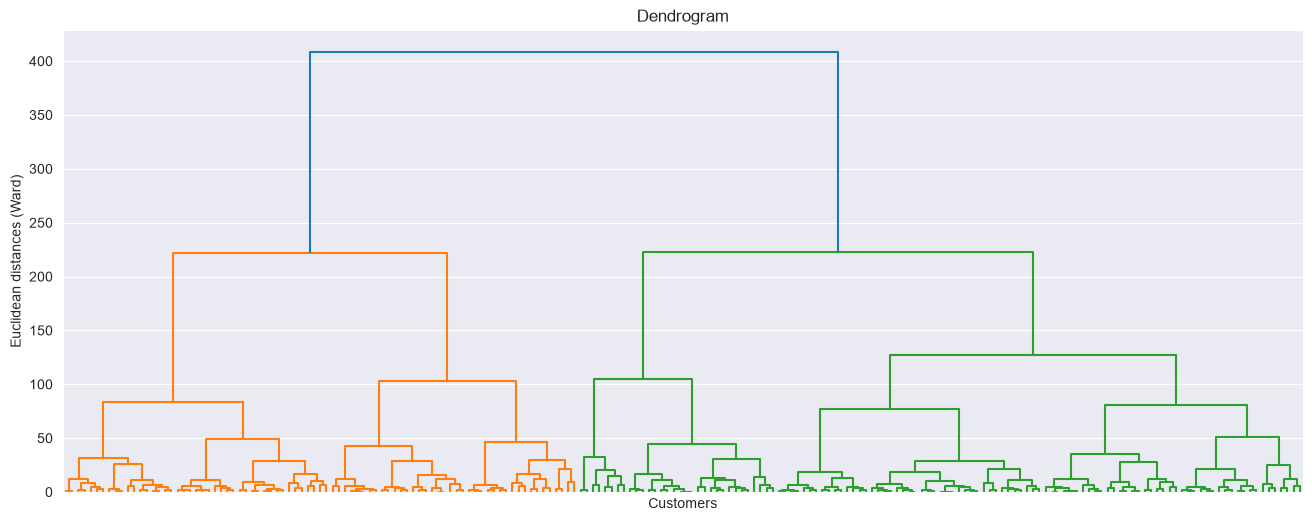

In [44]:
dendoOptimizer(X3)

**Choosing k:** the silhouette scores are low and flat here (0.40–0.43 for every k), meaning **age and income on their own don't form clearly separate groups**. k = 4 scores best (0.434), so we use **k = 4**, but these clusters should be read as rough bands rather than distinct segments. The low agreement between K-Means and hierarchical clustering below (ARI ≈ 0.57) supports this.

## Training the K-Means and Hierarchical models on Age and Annual Income (k = 4)

In [45]:
kmeans, labels = kmeansTrainer(4, X3)
hc, hc_labels = hierarchicalTrainer(4, X3)
compareModels(X3, labels, hc_labels)

K-Means silhouette                 0.434
Hierarchical silhouette            0.384
Agreement (Adjusted Rand Index)    0.567
dtype: float64

## Visualising the clusters for Age and Annual Income (KMeans Model)

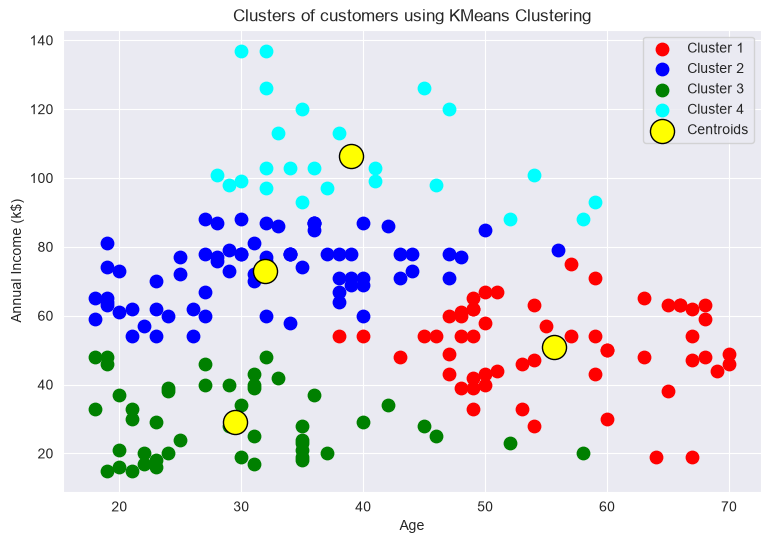

In [46]:
clusterVisualiser(X3, kmeans, 4, labels, 'Age', 'Annual Income (k$)', 'KMeans Clustering')

## Visualising the clusters for Age and Annual Income (Hierarchical Model)

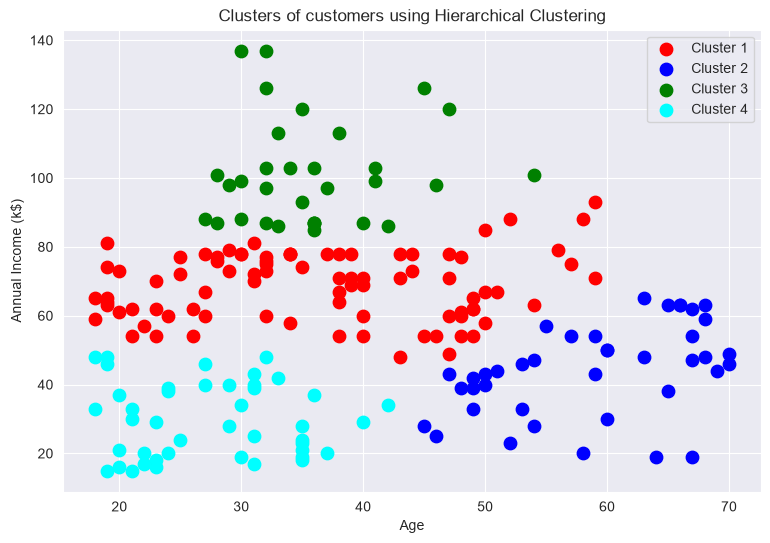

In [47]:
clusterVisualiser(X3, hc, 4, hc_labels, 'Age', 'Annual Income (k$)', 'Hierarchical Clustering')

## Cluster profiles for Age and Annual Income (KMeans Model)

In [48]:
clusterProfile(labels)

,Age,Annual Income (k$),Spending Score (1-100),Size,% Female
Cluster,,,,,
1,55.7,51.0,43.0,56,52.0
2,32.0,73.0,52.2,73,53.0
3,29.4,29.2,56.4,47,64.0
4,39.0,106.5,48.8,24,58.0


# Clustering the dataset on Age, Annual Income and Spending Score

With three features we **standardise** them first (mean 0, standard deviation 1), so that no feature dominates the distance just because its numbers are larger. The profiles and plots still use the original units.

In [49]:
X4 = StandardScaler().fit_transform(dataset[NUMERIC_COLS])

## Using the elbow method and silhouette scores to find the optimal number of clusters for Age, Annual Income and Spending Score

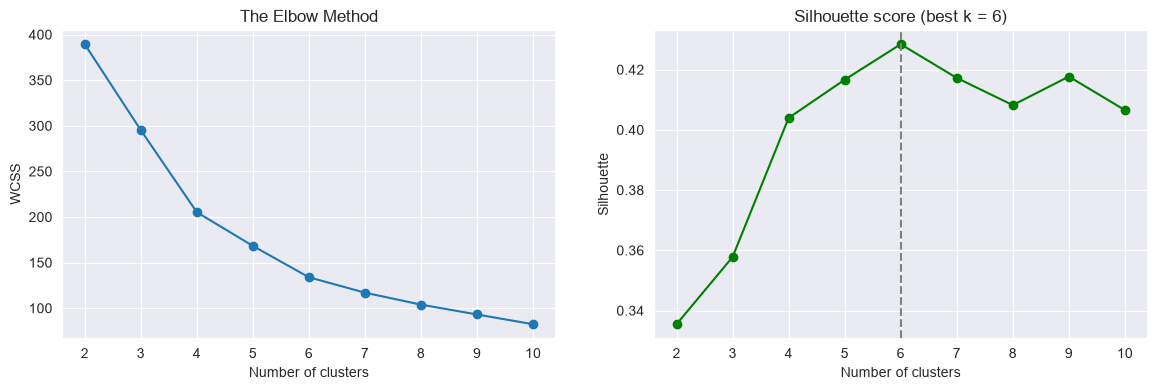

,WCSS,silhouette,davies_bouldin
k,,,
2,389.386,0.335,1.261
3,295.212,0.358,1.050
4,205.225,0.404,0.931
5,168.248,0.417,0.875
6,133.868,0.428,0.825
7,117.012,0.417,0.793
8,103.873,0.408,0.892
9,93.093,0.418,0.820
10,82.385,0.407,0.868


In [50]:
elbowOptimizer(X4)

## Using the dendrogram to find the optimal number of clusters for Age, Annual Income and Spending Score

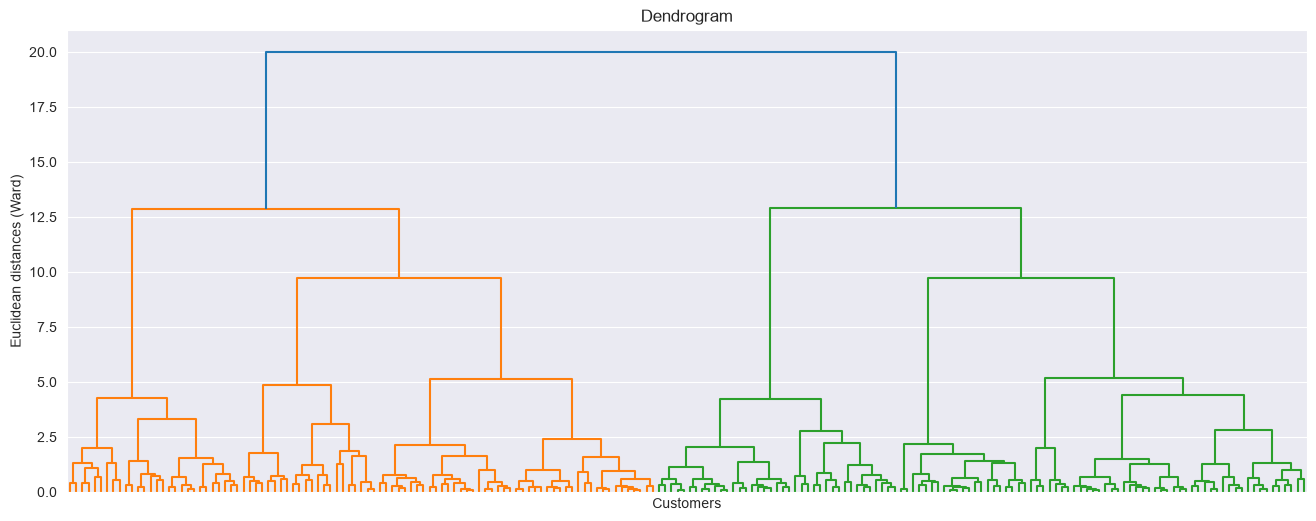

In [51]:
dendoOptimizer(X4)

**Choosing k:** on the standardised features, the silhouette score rises to a peak at **k = 6** (0.428) and then levels off, so we use **k = 6**.

## Training the K-Means and Hierarchical models on Age, Annual Income and Spending Score (k = 6)

In [52]:
kmeans, labels = kmeansTrainer(6, X4)
hc, hc_labels = hierarchicalTrainer(6, X4)   # trained on the features only, not on the K-Means labels
compareModels(X4, labels, hc_labels)

K-Means silhouette                 0.428
Hierarchical silhouette            0.420
Agreement (Adjusted Rand Index)    0.891
dtype: float64

In [53]:
results = dataset.assign(KMeans_Cluster=(labels + 1).astype(str), HC_Cluster=(hc_labels + 1).astype(str))
order = {"category_orders": {"KMeans_Cluster": sorted(results["KMeans_Cluster"].unique()),
                             "HC_Cluster": sorted(results["HC_Cluster"].unique())}}

## Visualising the clusters for Age, Annual Income and Spending Score (KMeans Model)

In [54]:
fig = px.scatter_3d(results, x=INCOME, y=SCORE, z=AGE, color="KMeans_Cluster", hover_data=["Gender"],
                    title="K-Means clusters (3 features)", **order)
fig.update_traces(marker_size=5)
fig.show()

## Visualising the clusters for Age, Annual Income and Spending Score (Hierarchical Model)

In [55]:
fig = px.scatter_3d(results, x=INCOME, y=SCORE, z=AGE, color="HC_Cluster", hover_data=["Gender"],
                    title="Hierarchical clusters (3 features)", **order)
fig.update_traces(marker_size=5)
fig.show()

## Cluster profiles for Age, Annual Income and Spending Score (KMeans Model)

In [56]:
profile = clusterProfile(labels)
profile

,Age,Annual Income (k$),Spending Score (1-100),Size,% Female
Cluster,,,,,
1,56.3,54.3,49.1,45,58.0
2,26.8,57.1,48.1,39,64.0
3,41.9,88.9,17.0,33,42.0
4,32.7,86.5,82.1,39,54.0
5,25.0,25.3,77.6,23,57.0
6,45.5,26.3,19.4,21,62.0


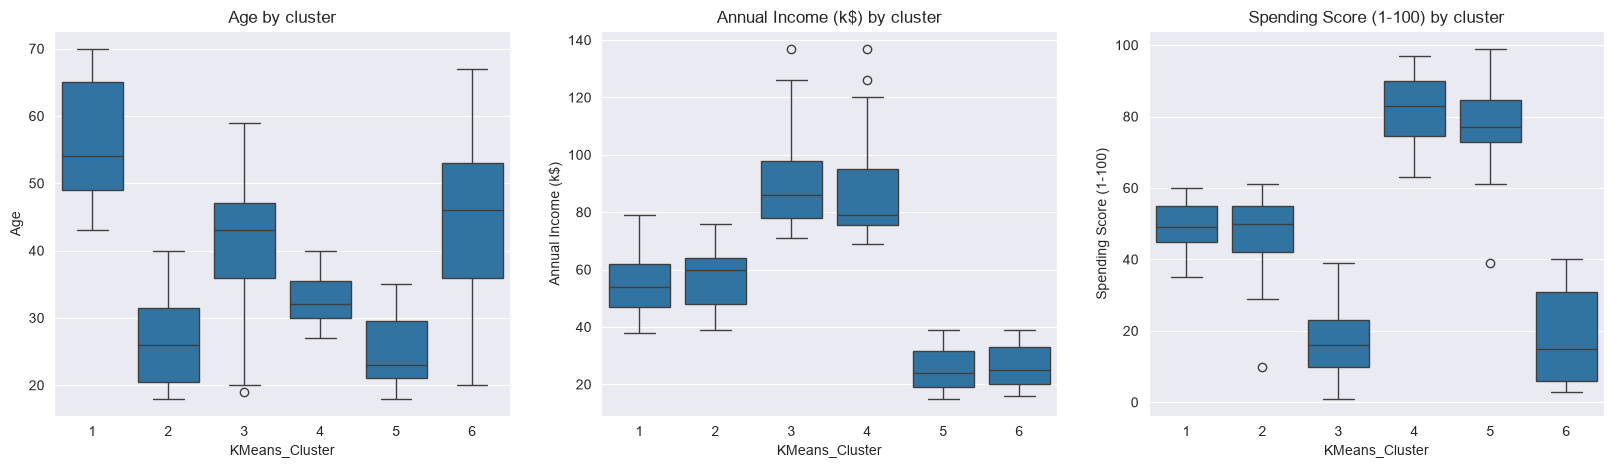

In [57]:
fig, axes = plt.subplots(1, 3, figsize=(20, 5))
for ax, col in zip(axes, NUMERIC_COLS):
    sns.boxplot(data=results, x="KMeans_Cluster", y=col, ax=ax,
                order=sorted(results["KMeans_Cluster"].unique()))
    ax.set_title(f"{col} by cluster")
plt.show()

# Conclusions and Business Recommendations

**Model comparison.** On every feature set where the data has real structure, K-Means and hierarchical (Ward) clustering find almost the same segments: ARI = 0.94 on Income vs Spending and 0.89 on all three features. That agreement shows the segments are a real feature of the data, not something one algorithm happened to produce. K-Means has an equal or higher silhouette score each time, and it can assign new customers to a segment directly (`kmeans.predict`), so it is the recommended model.

**Most useful feature sets.** *Annual Income vs Spending Score* gives the clearest segments (silhouette 0.55). The *three-feature* model gives the same picture and also splits the average group by age. *Age vs Annual Income* has little structure on its own.

**The six segments (K-Means, all three features):**

| Cluster | Profile | Avg age | Avg income (k$) | Avg score | Size | Suggested action |
|---|---|---|---|---|---|---|
| 4 | **Affluent big spenders** | 33 | 87 | 82 | 39 | Main target: loyalty/VIP programme, premium brands, early access to launches |
| 3 | **Affluent but cautious** | 42 | 89 | 17 | 33 | Biggest growth opportunity: they can afford more. Use quality-focused, personalised offers to win their spending |
| 5 | **Young, low income, high spend** | 25 | 25 | 78 | 23 | Trend-led, affordable products, social media campaigns. Watch for spending beyond their means |
| 6 | **Low income, low spend** | 46 | 26 | 19 | 21 | Lowest priority: value deals and essentials only |
| 1 | **Older average customers** | 56 | 54 | 49 | 45 | Comfort, convenience and service-led promotions |
| 2 | **Younger average customers** | 27 | 57 | 48 | 39 | Can be moved up toward the big-spender segment with bundles and entertainment/dining offers |

**Gender** barely differs between segments (42–64% female) and didn't separate customers in the EDA, so marketing doesn't need to split by gender.

**Limitations.** Only 200 customers and three behavioural features. The spending score is a single score assigned by the mall, not actual transaction data. Clusters were validated statistically only, with no business outcome to check them against. Next steps: add purchase-frequency and category data, and check that the segments stay stable on a larger sample.